# CIFAR-10: MLP, simple CNN, AlexNet, VGG16-BN, and ResNet-50

Compare five image classifiers trained from scratch using separate run cells.
The default **full mode** uses all 50,000 development images: **45,000 for
training and 5,000 for validation**. The official **10,000-image test set** is
kept separate. Each model trains for **120 epochs**.

VGG16-BN and ResNet-50 now match Kuang Liu's CIFAR implementations, including
their default PyTorch initialization. All five models keep his training
augmentation and normalization. All five models use Adam with a constant learning rate of 0.001
and weight decay 1e-5.
The existing split and 120-epoch budget remain in use.

**How to run:** restart the kernel, execute Sections 1–5, then run the model
cells in Section 6 individually, in any order. Run all five before the
comparison plots. A GPU is recommended. No full training results are included.

**Best models:** save the highest **validation accuracy** checkpoint to
`models/<model>_best.pth`; use lower validation loss to break accuracy ties.
Training continues for all requested epochs. Restore the selected state and
evaluate the test set once at the end. A loading example follows the run cells.

**Learning rate:** constant throughout training; there is no scheduler.
These Adam settings differ from Kuang Liu's SGD/cosine training recipe.

**Requirements:** PyTorch, torchvision, NumPy, pandas, Matplotlib, and IPython.
The first run downloads CIFAR-10 into `data/`; later runs reuse the cache.


## 1. What is being compared?

CIFAR-10 contains **32 × 32 RGB images** in 10 classes. All models receive the
same normalized `(B, 3, 32, 32)` tensors and output `(B, 10)` logits.

| Model label | Architecture in this notebook | CIFAR-specific choices |
|---|---|---|
| MLP | Flatten → 512 → 256 → 128 → 10 | 3,072 input pixels; no spatial weight sharing |
| Simple CNN | Two Conv–ReLU–Pool blocks; 128-unit classifier | Channels 32 → 64; a small baseline |
| AlexNet-CIFAR | Five convolutions and three linear layers | Exact class from the attachment: 3×3 kernels, channels 32/64/128/256/256, hidden sizes 2,048/1,024 |
| VGG16-BN-CIFAR | Kuang Liu VGG16: 13 convolutions in blocks 2/2/3/3/3; one linear layer | Conv → BN → ReLU; five max pools; 512 → 10 classifier; no dropout |
| ResNet50-CIFAR | Kuang Liu ResNet-50 with bottleneck blocks 3/4/6/3 | 3×3 stride-1 stem; no initial max-pool; fixed 4×4 average pool; 2048 → 10 classifier |

AlexNet and VGG16 here are explicitly **CIFAR adaptations**, not unchanged
ImageNet models. The ResNet-50 stem is adapted to avoid aggressive early
downsampling of a small image. None of these results is an ImageNet benchmark.


## 2. Setup and training budget

All five models use the same Adam optimizer settings:

| Setting | Value |
|---|---|
| Optimizer | Adam |
| Learning rate: all five models | 0.001 |
| Weight decay | 0.00001 |
| Adam betas / epsilon | PyTorch defaults: (0.9, 0.999) / 1e-8 |
| Training batch size | 128 |
| Scheduler | None; learning rates stay constant |
| Full-mode epochs | 120 |

Full mode keeps the disjoint 45,000/5,000 training/validation split. Checkpoint
selection maximizes **validation accuracy**, with lower validation loss as
the tie-breaker. The test set is evaluated only after checkpoint selection.
The Kuang Liu model definitions, training augmentation, and normalization are
retained. Seeds improve repeatability; results can differ across devices and versions.


In [10]:
# If needed, run in a separate cell and then restart the kernel:
# %pip install torch torchvision numpy pandas matplotlib

import gc
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torchvision
from torchvision import datasets, transforms as T
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from IPython.display import display, Markdown

RUN_MODE = 'full'  # 45,000 training + 5,000 validation images; 120 epochs.
PRESETS = {
    'demo': {'train_per_class': 500, 'val_per_class': 100, 'epochs': 5},
    'full': {'train_per_class': 4500, 'val_per_class': 500, 'epochs': 120},
}
assert RUN_MODE in PRESETS
config = PRESETS[RUN_MODE]
SEED = 42
BATCH_SIZE = 128
EPOCHS = config['epochs']
# Use the same constant Adam learning rate for all five models.
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
EXPERIMENT_ID = 'kuang_models_adam_valacc_aug_v3'
DATA_DIR = Path('data')
SAVE_CHECKPOINTS = True  # Highest validation accuracy; lower CE breaks ties.
MODELS_DIR = Path('models')
MODELS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available() else 'cpu')
CHANNELS_LAST = device.type in ('cpu', 'cuda')  # Storage layout; shape stays B,C,H,W.
if device.type == 'cpu':
    torch.set_num_threads(min(8, os.cpu_count() or 1))
if device.type == 'cuda':
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def prepare_model(model):
    model = model.to(device)
    if CHANNELS_LAST:
        model = model.to(memory_format=torch.channels_last)
    return model

def move_images(images):
    images = images.to(device)
    return images.contiguous(memory_format=torch.channels_last) if CHANNELS_LAST else images

set_seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print(f'PyTorch {torch.__version__}; torchvision {torchvision.__version__}; device={device}')
print(f'Mode={RUN_MODE}; epochs={EPOCHS}; batch size={BATCH_SIZE}; no pretrained weights')
print(f'Adam: lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY}; no scheduler')
print('Best checkpoint directory:', MODELS_DIR.resolve())


PyTorch 2.7.0; torchvision 0.22.0; device=mps
Mode=full; epochs=120; batch size=128; no pretrained weights
Adam: lr=0.001, weight_decay=1e-05; no scheduler
Best checkpoint directory: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/overview/models


## 3. Load CIFAR-10 and make a stratified split

The official development set has 50,000 images and the test set has 10,000.
Within each class, randomly reserve 500 development images for the validation
pool. The other 4,500 form the training pool. Demo mode uses a fixed subset of
each pool. Both modes keep training and validation disjoint.

All five models use Kuang Liu's training preprocessing, in this order:

1. **RandomCrop(32, padding=4):** zero-pad the image by four pixels on each side,
   then randomly crop a 32×32 region.
2. **RandomHorizontalFlip(p=0.5):** flip left/right with probability 0.5.
3. **ToTensor():** convert to a tensor and scale pixel values to [0, 1].
4. **Normalize:** mean (0.4914, 0.4822, 0.4465), standard deviation
   (0.2023, 0.1994, 0.2010), matching the repo.

Training draws a fresh random transformation each time an image is loaded;
the number of training examples per epoch stays 45,000. Validation and test
images use only **ToTensor → Normalize**, with no random crop or flip.
Separate dataset objects prevent training transforms from affecting validation.


In [11]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2023, 0.1994, 0.2010)
# Match kuangliu/pytorch-cifar/main.py: augmentation is training-only.
train_transform = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(p=0.5),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_transform = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

# Two views of the same official training split, with independent transforms.
# Download/check the data first; the training view then reuses the local files.
development_data = datasets.CIFAR10(
    DATA_DIR, train=True, download=True, transform=eval_transform)
training_data = datasets.CIFAR10(
    DATA_DIR, train=True, download=False, transform=train_transform)
test_data = datasets.CIFAR10(
    DATA_DIR, train=False, download=True, transform=eval_transform)
assert np.array_equal(training_data.targets, development_data.targets)
class_names = development_data.classes
targets = np.asarray(development_data.targets)
rng = np.random.default_rng(SEED)
train_indices, val_indices = [], []
for class_id in range(10):
    shuffled = rng.permutation(np.flatnonzero(targets == class_id))
    val_pool, train_pool = shuffled[:500], shuffled[500:]
    val_indices.extend(val_pool[:config['val_per_class']].tolist())
    train_indices.extend(train_pool[:config['train_per_class']].tolist())

assert set(train_indices).isdisjoint(val_indices)
train_subset = Subset(training_data, train_indices)
val_subset = Subset(development_data, val_indices)

def make_train_loader():
    # New loader + generator per model: identical batch order across models.
    return DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)

val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f'{RUN_MODE.upper()}: train={len(train_subset):,}, validation={len(val_subset):,}, '
      f'test={len(test_data):,}, epochs={EPOCHS}')
print('Training preprocessing:', train_transform)
print('Validation/test preprocessing:', eval_transform)
display(pd.DataFrame({
    'Class': class_names,
    'Training': np.bincount(targets[train_indices], minlength=10),
    'Validation': np.bincount(targets[val_indices], minlength=10),
}))


FULL: train=45,000, validation=5,000, test=10,000, epochs=120
Training preprocessing: Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.2023, 0.1994, 0.201))
)
Validation/test preprocessing: Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.2023, 0.1994, 0.201))
)


,Class,Training,Validation
0,airplane,4500,500
1,automobile,4500,500
2,bird,4500,500
3,cat,4500,500
4,deer,4500,500
5,dog,4500,500
6,frog,4500,500
7,horse,4500,500
8,ship,4500,500
9,truck,4500,500


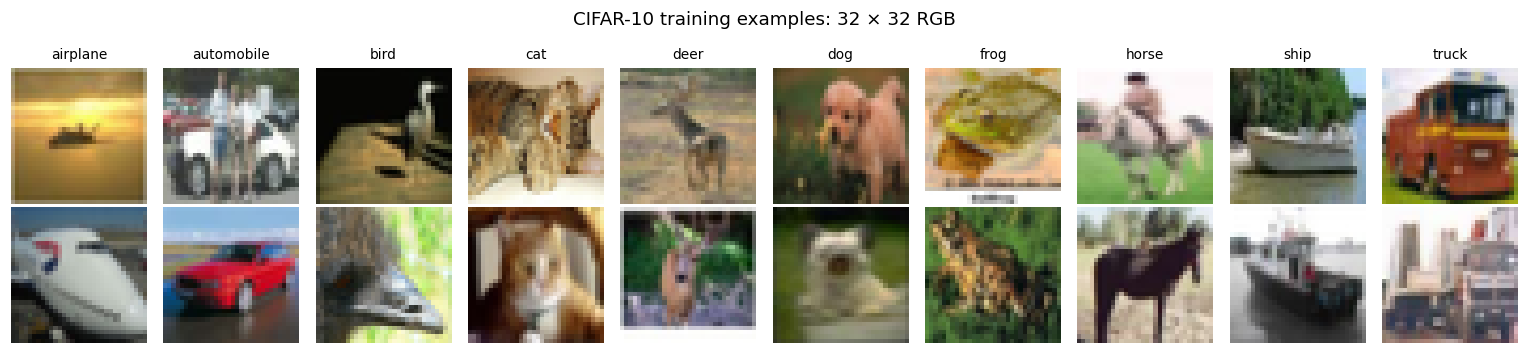

In [12]:
# Show two TRAINING examples per class using raw RGB data for correct colors.
fig, axes = plt.subplots(2, 10, figsize=(14, 3.3))
for class_id in range(10):
    chosen = [i for i in train_indices if targets[i] == class_id][:2]
    for row, index in enumerate(chosen):
        axes[row, class_id].imshow(development_data.data[index])
        axes[row, class_id].axis('off')
        if row == 0:
            axes[row, class_id].set_title(class_names[class_id], fontsize=9)
fig.suptitle('CIFAR-10 training examples: 32 × 32 RGB')
plt.tight_layout()
plt.show()

## 4. Define the five models

### MLP and simple CNN

The MLP flattens all `3 × 32 × 32 = 3072` pixel values. The simple CNN learns
local filters, shares them across the image, and pools from 32×32 to 16×16 to
8×8. Its classifier receives `64 × 8 × 8 = 4096` features.
Both output raw logits; no final softmax is needed for cross-entropy loss.

In [13]:
class CIFAR_MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

### AlexNet-CIFAR: the class from your notebook

This preserves the supplied five convolutional layers, three pooling layers,
and three linear layers. The two dropout layers act during training and are
disabled by `model.eval()`. The feature shapes are
`3×32×32 → 32×16×16 → 64×8×8 → 128×8×8 → 256×8×8 → 256×4×4`.

In [14]:
import torch
import torch.nn as nn

class AlexNet_CIFAR(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # --------------------------------------------------
        # Feature extractor: 5 convolutional layers + 3 pooling layers
        # --------------------------------------------------
        self.features = nn.Sequential(
            # Conv1: channels (3 -> 32) size (32×32 -> 32×32 -> 16×16)
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  

            # Conv2: channels (32 -> 64) size (16×16 -> 16×16 -> 8×8)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # Output size: 8×8

            # Conv3: channels (64 -> 128) size (8x8 -> 8x8)
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # Conv4: channels (128 -> 256) size (8x8 -> 8x8)
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # Conv5: channels (256 -> 256) size (8x8 -> 8x8 -> 4x4)
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2) 
        )

        # --------------------------------------------------
        # Classifier: flatten 256*4*4 -> num_classes
        # --------------------------------------------------
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),                          # First dropout
            nn.Linear(256 * 4 * 4, 2048),               # Fully connected: 256*4*4 -> 2048
            nn.ReLU(inplace=True),

            nn.Dropout(p=0.5),                          # Second dropout
            nn.Linear(2048, 1024),                      # Fully connected: 2048 -> 1024
            nn.ReLU(inplace=True),

            nn.Linear(1024, num_classes)                # Final linear layer: 1024 -> num_classes
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)  
        x = self.classifier(x)
        return x

### VGG16-BN-CIFAR: Kuang Liu's VGG16 configuration

The five blocks contain **2, 2, 3, 3, 3** convolutions. Each convolution uses
a 3×3 kernel with padding 1, followed by **BatchNorm2d → ReLU**. Each block
ends in 2×2 max pooling. Five pools reduce 32×32 to 1×1, giving 512 features.

The classifier is now a single **512 → 10** linear layer. There is **no
dropout**, and PyTorch's default layer initialization is used, as in the repo.
The final 1×1 average pool is also retained (it leaves these features unchanged).
Kuang Liu calls this configuration VGG16 based on its convolutional backbone;
the CIFAR version has 13 convolutional and one linear layer, not the original
ImageNet model's three-layer classifier. BN statistics are saved in checkpoints.


In [15]:
# Architecture adapted from kuangliu/pytorch-cifar/models/vgg.py (MIT; notice below).
class VGG16BN_CIFAR(nn.Module):
    def __init__(self):
        super().__init__()
        # Standard VGG16 convolution widths and block depths.
        layout = [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M',
                  512, 512, 512, 'M', 512, 512, 512, 'M']
        layers, in_channels = [], 3
        for entry in layout:
            if entry == 'M':
                layers.append(nn.MaxPool2d(2, 2))
            else:
                layers.extend([
                    nn.Conv2d(in_channels, entry, 3, padding=1),
                    nn.BatchNorm2d(entry),
                    nn.ReLU(inplace=True)
                ])
                in_channels = entry
        layers.append(nn.AvgPool2d(kernel_size=1, stride=1))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(512, 10)
        # Keep default PyTorch initialization, matching Kuang Liu's VGG.

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)


### ResNet50-CIFAR: Kuang Liu's implementation

A residual block combines a learned transformation with a shortcut:
$h_{\mathrm{out}}=\mathrm{ReLU}(F(h_{\mathrm{in}})+S(h_{\mathrm{in}}))$.
$S$ is the identity when dimensions match and a learned projection otherwise.
ResNet-50 uses bottlenecks with 1×1, 3×3, and 1×1 convolutions.

The code below uses Kuang Liu's **3/4/6/3 bottleneck blocks**, 3×3 stride-1
input convolution, and no initial max-pool. Stage sizes are 32×32, 16×16,
8×8, and 4×4. Fixed 4×4 average pooling then gives 2,048 features for the
**2048 → 10** classifier. Downsampling strides are in the 3×3 convolutions.
The implementation keeps default PyTorch initialization, exactly as in the
repo; it no longer uses torchvision's custom initialization.


In [16]:
# From kuangliu/pytorch-cifar/models/resnet.py (MIT; full notice below).
class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, in_planes, planes, stride=1):
        super(Bottleneck, self).__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.conv3 = nn.Conv2d(planes, self.expansion *
                               planes, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(self.expansion*planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion*planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, self.expansion*planes,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(self.expansion*planes)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = F.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        out += self.shortcut(x)
        out = F.relu(out)
        return out


class ResNet(nn.Module):
    def __init__(self, block, num_blocks, num_classes=10):
        super(ResNet, self).__init__()
        self.in_planes = 64

        self.conv1 = nn.Conv2d(3, 64, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.layer1 = self._make_layer(block, 64, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 128, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 256, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(block, 512, num_blocks[3], stride=2)
        self.linear = nn.Linear(512*block.expansion, num_classes)

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1]*(num_blocks-1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_planes, planes, stride))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = F.avg_pool2d(out, 4)
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out


def ResNet50():
    return ResNet(Bottleneck, [3, 4, 6, 3])


def make_resnet50_cifar():
    return ResNet50()

MODEL_FACTORIES = {
    'MLP': CIFAR_MLP,
    'Simple CNN': SimpleCNN,
    'AlexNet-CIFAR': AlexNet_CIFAR,
    'VGG16-BN-CIFAR': VGG16BN_CIFAR,
    'ResNet50-CIFAR': make_resnet50_cifar,
}

CHECKPOINT_FILENAMES = {
    'MLP': 'MLP_best.pth',
    'Simple CNN': 'SimpleCNN_best.pth',
    'AlexNet-CIFAR': 'AlexNet_CIFAR_best.pth',
    'VGG16-BN-CIFAR': 'VGG16_BN_CIFAR_best.pth',
    'ResNet50-CIFAR': 'ResNet50_CIFAR_best.pth',
}

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Check every architecture before starting expensive training.
architecture_rows = []
for name, factory in MODEL_FACTORIES.items():
    set_seed(SEED)
    demo_model = factory().eval()
    with torch.inference_mode():
        output = demo_model(torch.zeros(2, 3, 32, 32))
    assert output.shape == (2, 10)
    assert torch.isfinite(output).all()
    architecture_rows.append({'Model': name, 'Parameters': count_parameters(demo_model),
                              'Output shape': str(tuple(output.shape))})
    del demo_model
    gc.collect()
architecture_table = pd.DataFrame(architecture_rows).set_index('Model')
display(architecture_table)


,Parameters,Output shape
Model,,
MLP,1738890,"(2, 10)"
Simple CNN,545098,"(2, 10)"
AlexNet-CIFAR,11477578,"(2, 10)"
VGG16-BN-CIFAR,14728266,"(2, 10)"
ResNet50-CIFAR,23520842,"(2, 10)"


## 5. Shared training, evaluation, and checkpoint saving

Each mini-batch computes logits, cross-entropy, gradients, and an Adam update.
Losses and accuracy are weighted by batch size. The model uses training mode
for fitting and evaluation mode for validation and testing. Each model's
learning rate stays constant throughout training; there is no scheduler.

Every time **validation accuracy increases**, copy the complete state (including
BN running statistics) and save it in `models/`. If accuracy ties, select the
lower validation loss; if both tie, keep the earlier epoch. The checkpoint
records the selected epoch and validation metrics, experiment identifier,
optimizer settings, training/evaluation transforms, normalization,
class names, and split indices.
Saving at each improvement preserves the best completed epoch if interrupted.

Training runs for all requested epochs; this is checkpoint selection, not early
stopping. Restore the selected state and evaluate the test set once afterward.
Rerunning a model cell starts fresh and replaces that model's checkpoint and
its entry in `runs`. Checkpoints store weights and metadata for inference,
not optimizer state for resuming training.


In [17]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for images, labels in loader:
        images, labels = move_images(images), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        size = labels.size(0)
        total_loss += loss.item() * size
        correct += (logits.argmax(1) == labels).sum().item()
        n += size
    return total_loss / n, 100 * correct / n


@torch.inference_mode()
def evaluate(model, loader, criterion, collect_predictions=False):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    predictions, observed = [], []
    for images, labels in loader:
        images, labels = move_images(images), labels.to(device)
        logits = model(images)
        predicted = logits.argmax(1)
        size = labels.size(0)
        total_loss += criterion(logits, labels).item() * size
        correct += (predicted == labels).sum().item()
        n += size
        if collect_predictions:
            predictions.append(predicted.cpu())
            observed.append(labels.cpu())
    metrics = (total_loss / n, 100 * correct / n)
    if collect_predictions:
        return (*metrics, torch.cat(predictions), torch.cat(observed))
    return metrics


def synchronize():
    if device.type == 'cuda': torch.cuda.synchronize()
    elif device.type == 'mps': torch.mps.synchronize()


def fit_and_test(name, factory):
    set_seed(SEED)
    model = prepare_model(factory())
    n_parameters = count_parameters(model)
    loader = make_train_loader()
    criterion = nn.CrossEntropyLoss()
    learning_rate = LEARNING_RATE
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate, weight_decay=WEIGHT_DECAY)
    checkpoint_path = MODELS_DIR / CHECKPOINT_FILENAMES[name]
    history = {key: [] for key in ('train_loss', 'train_acc', 'val_loss', 'val_acc', 'lr')}
    best_acc, best_loss = float('-inf'), float('inf')
    best_epoch, best_state = 0, None
    synchronize()
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        epoch_lr = optimizer.param_groups[0]['lr']
        train_loss, train_acc = train_one_epoch(model, loader, criterion, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        if not np.isfinite([train_loss, train_acc, val_loss, val_acc]).all():
            raise RuntimeError(f'{name}: nonfinite training/validation metric; check the optimization settings.')
        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc, epoch_lr]):
            history[key].append(value)
        is_best = (val_acc > best_acc or
                   (val_acc == best_acc and val_loss < best_loss))
        if is_best:
            best_acc, best_loss, best_epoch = val_acc, val_loss, epoch
            best_state = {key: value.detach().cpu().clone()
                          for key, value in model.state_dict().items()}
            if SAVE_CHECKPOINTS:
                checkpoint = {
                    'model_name': name,
                    'experiment_id': EXPERIMENT_ID,
                    'selection_metric': 'val_accuracy',
                    'tie_breaker': 'val_loss',
                    'model_state_dict': best_state,
                    'best_epoch': best_epoch,
                    'val_loss': float(best_loss),
                    'val_accuracy': float(best_acc),
                    'run_mode': RUN_MODE,
                    'epochs_requested': EPOCHS,
                    'optimizer': 'Adam',
                    'scheduler': None,
                    'epoch_learning_rate': epoch_lr,
                    'learning_rate': learning_rate,
                    'weight_decay': WEIGHT_DECAY,
                    'batch_size': BATCH_SIZE,
                    'seed': SEED,
                    'class_names': list(class_names),
                    'mean': list(MEAN),
                    'std': list(STD),
                    'train_transform': repr(train_transform),
                    'eval_transform': repr(eval_transform),
                    'train_indices': list(train_indices),
                    'val_indices': list(val_indices),
                }
                MODELS_DIR.mkdir(parents=True, exist_ok=True)
                temporary_path = checkpoint_path.with_suffix('.pth.tmp')
                torch.save(checkpoint, temporary_path)
                temporary_path.replace(checkpoint_path)
                del checkpoint
        print(f'{name} | {epoch:3d}/{EPOCHS} | lr {epoch_lr:.6f} | train CE {train_loss:.4f} | '
              f'val CE {val_loss:.4f} | val accuracy {val_acc:.2f}%', flush=True)
    synchronize()
    fit_seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    test_loss, test_acc, predictions, observed = evaluate(model, test_loader, criterion, True)

    run = {'history': history, 'best_epoch': best_epoch, 'parameters': n_parameters,
           'experiment_id': EXPERIMENT_ID, 'selection_metric': 'val_accuracy',
           'run_mode': RUN_MODE, 'epochs': EPOCHS,
           'best_val_acc': best_acc, 'best_val_loss': best_loss,
           'optimizer': 'Adam', 'scheduler': None,
           'learning_rate': learning_rate,
           'checkpoint_path': str(checkpoint_path) if SAVE_CHECKPOINTS else None,
           'fit_seconds': fit_seconds, 'test_loss': test_loss, 'test_acc': test_acc,
           'predictions': predictions, 'labels': observed}
    print(f'{name}: restored epoch {best_epoch} (best val accuracy {best_acc:.2f}%); '
          f'final test accuracy {test_acc:.2f}%; '
          f'fit time {fit_seconds:.1f} s', flush=True)
    if SAVE_CHECKPOINTS:
        print(f'Best checkpoint saved: {checkpoint_path}', flush=True)
    del model, optimizer, best_state
    gc.collect()
    if device.type == 'cuda': torch.cuda.empty_cache()
    elif device.type == 'mps': torch.mps.empty_cache()
    return run


## 6. Train each model in its own cell

Run Sections 1–5 first. The initialization cell below preserves any existing
results in this kernel. Each following cell trains only its named model for
120 epochs in full mode, saves its best checkpoint, and updates `runs`.
Run these five cells in any order; execute all five before the comparison section.
Restart the kernel before using this updated notebook. The comparison section
rejects results from the previous architecture/optimizer/checkpoint recipe.
To clear in-memory results explicitly, run `runs = {}` in a separate cell.


In [18]:
if 'runs' not in globals():
    runs = {}


### 6.1. MLP

In [19]:
runs['MLP'] = fit_and_test('MLP', MODEL_FACTORIES['MLP'])


MLP |   1/120 | lr 0.001000 | train CE 1.8153 | val CE 1.6938 | val accuracy 40.10%
MLP |   2/120 | lr 0.001000 | train CE 1.6494 | val CE 1.6781 | val accuracy 39.16%
MLP |   3/120 | lr 0.001000 | train CE 1.5747 | val CE 1.6097 | val accuracy 42.64%
MLP |   4/120 | lr 0.001000 | train CE 1.5291 | val CE 1.5757 | val accuracy 43.86%
MLP |   5/120 | lr 0.001000 | train CE 1.4979 | val CE 1.5578 | val accuracy 44.72%
MLP |   6/120 | lr 0.001000 | train CE 1.4699 | val CE 1.5360 | val accuracy 45.64%
MLP |   7/120 | lr 0.001000 | train CE 1.4487 | val CE 1.5219 | val accuracy 46.76%
MLP |   8/120 | lr 0.001000 | train CE 1.4232 | val CE 1.5230 | val accuracy 46.04%
MLP |   9/120 | lr 0.001000 | train CE 1.4060 | val CE 1.4806 | val accuracy 47.46%
MLP |  10/120 | lr 0.001000 | train CE 1.3925 | val CE 1.5264 | val accuracy 46.02%
MLP |  11/120 | lr 0.001000 | train CE 1.3756 | val CE 1.4983 | val accuracy 46.06%
MLP |  12/120 | lr 0.001000 | train CE 1.3692 | val CE 1.4783 | val accuracy

### 6.2. Simple CNN

In [20]:
runs['Simple CNN'] = fit_and_test('Simple CNN', MODEL_FACTORIES['Simple CNN'])


Simple CNN |   1/120 | lr 0.001000 | train CE 1.5945 | val CE 1.2855 | val accuracy 53.78%
Simple CNN |   2/120 | lr 0.001000 | train CE 1.2674 | val CE 1.0700 | val accuracy 61.88%
Simple CNN |   3/120 | lr 0.001000 | train CE 1.1197 | val CE 0.9613 | val accuracy 65.44%
Simple CNN |   4/120 | lr 0.001000 | train CE 1.0340 | val CE 0.9012 | val accuracy 68.18%
Simple CNN |   5/120 | lr 0.001000 | train CE 0.9780 | val CE 0.8643 | val accuracy 69.62%
Simple CNN |   6/120 | lr 0.001000 | train CE 0.9300 | val CE 0.8066 | val accuracy 71.78%
Simple CNN |   7/120 | lr 0.001000 | train CE 0.8940 | val CE 0.8014 | val accuracy 72.16%
Simple CNN |   8/120 | lr 0.001000 | train CE 0.8629 | val CE 0.7882 | val accuracy 72.86%
Simple CNN |   9/120 | lr 0.001000 | train CE 0.8347 | val CE 0.7489 | val accuracy 73.12%
Simple CNN |  10/120 | lr 0.001000 | train CE 0.8095 | val CE 0.7344 | val accuracy 74.22%
Simple CNN |  11/120 | lr 0.001000 | train CE 0.7936 | val CE 0.7060 | val accuracy 75.26%

### 6.3. AlexNet-CIFAR

In [21]:
runs['AlexNet-CIFAR'] = fit_and_test('AlexNet-CIFAR', MODEL_FACTORIES['AlexNet-CIFAR'])


AlexNet-CIFAR |   1/120 | lr 0.001000 | train CE 1.7436 | val CE 1.4257 | val accuracy 46.92%
AlexNet-CIFAR |   2/120 | lr 0.001000 | train CE 1.3648 | val CE 1.1995 | val accuracy 56.24%
AlexNet-CIFAR |   3/120 | lr 0.001000 | train CE 1.1778 | val CE 1.0814 | val accuracy 61.14%
AlexNet-CIFAR |   4/120 | lr 0.001000 | train CE 1.0438 | val CE 0.8858 | val accuracy 69.06%
AlexNet-CIFAR |   5/120 | lr 0.001000 | train CE 0.9467 | val CE 0.8149 | val accuracy 71.20%
AlexNet-CIFAR |   6/120 | lr 0.001000 | train CE 0.8742 | val CE 0.7783 | val accuracy 72.32%
AlexNet-CIFAR |   7/120 | lr 0.001000 | train CE 0.8289 | val CE 0.7571 | val accuracy 74.00%
AlexNet-CIFAR |   8/120 | lr 0.001000 | train CE 0.7797 | val CE 0.7243 | val accuracy 74.52%
AlexNet-CIFAR |   9/120 | lr 0.001000 | train CE 0.7362 | val CE 0.6984 | val accuracy 75.78%
AlexNet-CIFAR |  10/120 | lr 0.001000 | train CE 0.7130 | val CE 0.6418 | val accuracy 77.56%
AlexNet-CIFAR |  11/120 | lr 0.001000 | train CE 0.6817 | va

### 6.4. VGG16-BN-CIFAR

In [22]:
runs['VGG16-BN-CIFAR'] = fit_and_test('VGG16-BN-CIFAR', MODEL_FACTORIES['VGG16-BN-CIFAR'])


VGG16-BN-CIFAR |   1/120 | lr 0.001000 | train CE 1.6230 | val CE 1.3983 | val accuracy 51.16%
VGG16-BN-CIFAR |   2/120 | lr 0.001000 | train CE 1.0870 | val CE 1.2526 | val accuracy 59.40%
VGG16-BN-CIFAR |   3/120 | lr 0.001000 | train CE 0.8721 | val CE 1.1532 | val accuracy 63.56%
VGG16-BN-CIFAR |   4/120 | lr 0.001000 | train CE 0.7410 | val CE 0.6991 | val accuracy 76.80%
VGG16-BN-CIFAR |   5/120 | lr 0.001000 | train CE 0.6456 | val CE 0.7771 | val accuracy 74.66%
VGG16-BN-CIFAR |   6/120 | lr 0.001000 | train CE 0.5786 | val CE 0.5978 | val accuracy 80.12%
VGG16-BN-CIFAR |   7/120 | lr 0.001000 | train CE 0.5305 | val CE 0.5759 | val accuracy 80.74%
VGG16-BN-CIFAR |   8/120 | lr 0.001000 | train CE 0.4825 | val CE 0.5334 | val accuracy 82.54%
VGG16-BN-CIFAR |   9/120 | lr 0.001000 | train CE 0.4472 | val CE 0.4879 | val accuracy 84.22%
VGG16-BN-CIFAR |  10/120 | lr 0.001000 | train CE 0.4147 | val CE 0.4361 | val accuracy 85.12%
VGG16-BN-CIFAR |  11/120 | lr 0.001000 | train CE 

### 6.5. ResNet50-CIFAR

In [23]:
runs['ResNet50-CIFAR'] = fit_and_test('ResNet50-CIFAR', MODEL_FACTORIES['ResNet50-CIFAR'])


ResNet50-CIFAR |   1/120 | lr 0.001000 | train CE 1.6616 | val CE 1.2975 | val accuracy 52.34%
ResNet50-CIFAR |   2/120 | lr 0.001000 | train CE 1.1020 | val CE 1.4229 | val accuracy 57.20%
ResNet50-CIFAR |   3/120 | lr 0.001000 | train CE 0.9050 | val CE 0.8862 | val accuracy 69.34%
ResNet50-CIFAR |   4/120 | lr 0.001000 | train CE 0.7748 | val CE 0.7705 | val accuracy 72.66%
ResNet50-CIFAR |   5/120 | lr 0.001000 | train CE 0.6696 | val CE 0.8043 | val accuracy 72.54%
ResNet50-CIFAR |   6/120 | lr 0.001000 | train CE 0.5932 | val CE 0.6656 | val accuracy 78.30%
ResNet50-CIFAR |   7/120 | lr 0.001000 | train CE 0.5314 | val CE 0.5507 | val accuracy 81.20%
ResNet50-CIFAR |   8/120 | lr 0.001000 | train CE 0.4894 | val CE 0.4959 | val accuracy 83.24%
ResNet50-CIFAR |   9/120 | lr 0.001000 | train CE 0.4524 | val CE 0.5537 | val accuracy 82.66%
ResNet50-CIFAR |  10/120 | lr 0.001000 | train CE 0.4216 | val CE 0.4929 | val accuracy 82.92%
ResNet50-CIFAR |  11/120 | lr 0.001000 | train CE 

### Load a saved best model

The helper restores weights and BN statistics on the current device. In a fresh
kernel, execute the setup and model-definition cells first. The example is
commented out so running the notebook does not retain an extra model in memory.

Checkpoints are under `models/` relative to the working directory. Rerun the
model's training cell to create its new checkpoint. Old VGG and torchvision
ResNet checkpoints do not match these model definitions; the helper rejects
checkpoints from earlier experiments, including the old normalization and
unaugmented training setup. Retrain with the new preprocessing. Changing the
selection rule cannot
recover weights from an earlier run that were never saved.

If using a temporary environment, download `models/` before ending the session.


In [24]:
def load_best_model(name):
    checkpoint_path = MODELS_DIR / CHECKPOINT_FILENAMES[name]
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    if checkpoint['model_name'] != name:
        raise ValueError('Checkpoint model does not match the requested architecture.')
    if checkpoint.get('experiment_id') != EXPERIMENT_ID:
        raise ValueError('Checkpoint uses an older model/training recipe. '
                         'Rerun this model cell to save a new checkpoint.')
    if checkpoint.get('learning_rate') != LEARNING_RATE:
        raise ValueError('Checkpoint learning rate differs from the current setting. '
                         'Rerun this model cell to save a new checkpoint.')
    model = MODEL_FACTORIES[name]()
    model.load_state_dict(checkpoint['model_state_dict'])
    model = prepare_model(model)
    model.eval()
    return model, checkpoint

# Example:
# best_vgg, checkpoint = load_best_model('VGG16-BN-CIFAR')
# print(checkpoint['best_epoch'], checkpoint['val_accuracy'], checkpoint['selection_metric'])
# with torch.inference_mode():
#     logits = best_vgg(move_images(images))  # images normalized with MEAN and STD


## 7. Compare measured results

All numbers below come from this notebook's completed run, under the mode
printed in the table. Each model is restored to its highest **validation accuracy**
checkpoint, breaking accuracy ties with lower validation loss. The validation
loss and test metrics below describe that same selected checkpoint.

The test set is balanced, so a uniform random classifier has 10% expected
accuracy. Treat a result near 10% as a failure to learn useful classification
under this recipe, not as evidence that the architecture cannot solve CIFAR-10.


In [25]:
missing = [name for name in MODEL_FACTORIES if name not in runs]
if missing:
    raise RuntimeError(f'Run these model cells before the comparisons: {missing}')
stale = [name for name, run in runs.items() if name in MODEL_FACTORIES and
         (run.get('experiment_id') != EXPERIMENT_ID or
          run.get('epochs') != EPOCHS or run.get('run_mode') != RUN_MODE or
          run.get('learning_rate') != LEARNING_RATE)]
if stale:
    raise RuntimeError(f'Rerun these models with the current settings: {stale}')
# Keep plotting order stable even if the model cells were run in a different order.
runs = {name: runs[name] for name in MODEL_FACTORIES}
rows = []
for name, run in runs.items():
    best_index = run['best_epoch'] - 1
    rows.append({
        'Model': name, 'Mode': RUN_MODE, 'Train images': len(train_subset),
        'Epochs': EPOCHS, 'Best epoch': run['best_epoch'],
        'Initial learning rate': run['learning_rate'], 'Optimizer': run['optimizer'],
        'Parameters': run['parameters'],
        'Validation CE': run['history']['val_loss'][best_index],
        'Validation accuracy (%)': run['history']['val_acc'][best_index],
        'Test CE': run['test_loss'], 'Test accuracy (%)': run['test_acc'],
        'Fit time (s)': run['fit_seconds'],
        'Best checkpoint': run['checkpoint_path'],
    })
results = pd.DataFrame(rows).set_index('Model')
assert all(torch.equal(run['labels'], runs['MLP']['labels']) for run in runs.values())
assert len(runs['MLP']['labels']) == 10000
display(Markdown(f'**{RUN_MODE.upper()} results — {len(train_subset):,} training images, '
                 f'{len(val_subset):,} validation images, {EPOCHS} epochs per model; '
                 '10,000 test images.**'))
display(results.round({'Validation CE': 4, 'Validation accuracy (%)': 2,
                      'Test CE': 4, 'Test accuracy (%)': 2, 'Fit time (s)': 1}))


**FULL results — 45,000 training images, 5,000 validation images, 120 epochs per model; 10,000 test images.**

,Mode,Train images,Epochs,Best epoch,Initial learning rate,Optimizer,Parameters,Validation CE,Validation accuracy (%),Test CE,Test accuracy (%),Fit time (s),Best checkpoint
Model,,,,,,,,,,,,,
MLP,full,45000,120,85,0.001,Adam,1738890,1.3573,53.80,1.3538,53.29,563.8,models/MLP_best.pth
Simple CNN,full,45000,120,109,0.001,Adam,545098,0.5678,82.34,0.6000,81.24,671.8,models/SimpleCNN_best.pth
AlexNet-CIFAR,full,45000,120,91,0.001,Adam,11477578,0.4847,85.84,0.5202,85.06,1418.9,models/AlexNet_CIFAR_best.pth
VGG16-BN-CIFAR,full,45000,120,116,0.001,Adam,14728266,0.3611,91.88,0.3944,90.60,3839.3,models/VGG16_BN_CIFAR_best.pth
ResNet50-CIFAR,full,45000,120,115,0.001,Adam,23520842,0.3119,92.62,0.3606,91.84,23287.7,models/ResNet50_CIFAR_best.pth


### Learning curves

Training metrics average predictions made as weights change across mini-batches;
validation uses a fixed end-of-epoch model. Dropout is active only during
training, and VGG/ResNet batch normalization also behaves differently in the
two modes. Training images also receive random crops and flips, while validation images
do not. Thus a validation loss below training loss is not itself an error.

Dots on the validation accuracy plot mark the saved checkpoints.


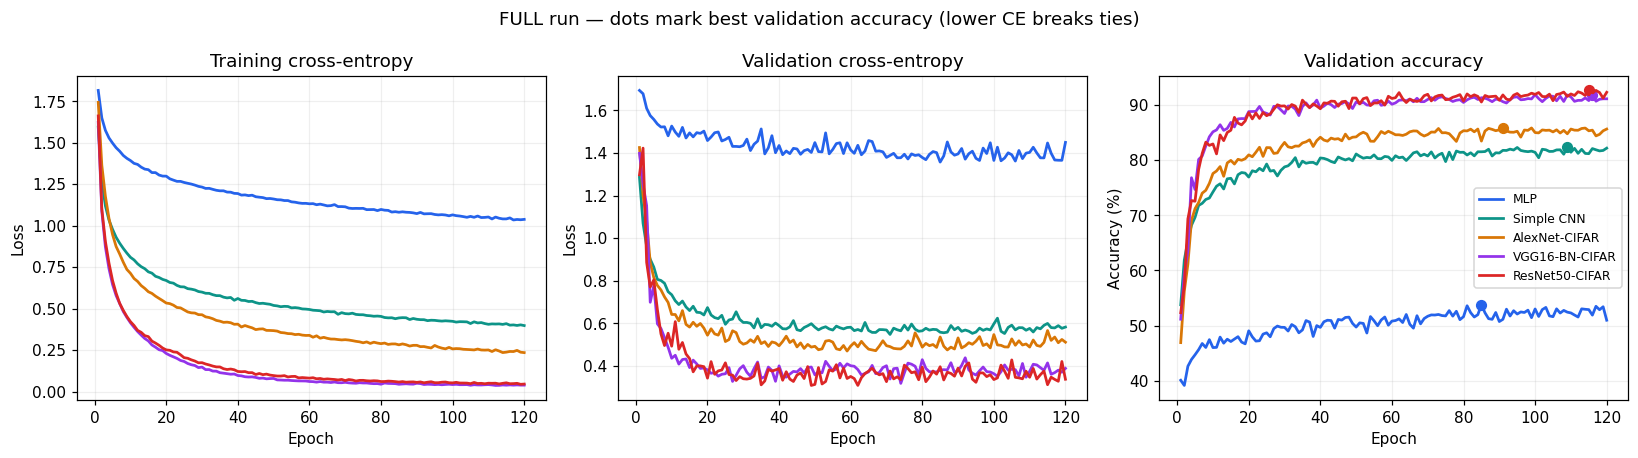

In [26]:
palette = dict(zip(runs, ['#2563eb', '#0d9488', '#d97706', '#9333ea', '#dc2626']))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
epochs_axis = np.arange(1, EPOCHS + 1)
for name, run in runs.items():
    color = palette[name]
    for ax, metric in zip(axes, ['train_loss', 'val_loss', 'val_acc']):
        ax.plot(epochs_axis, run['history'][metric], color=color, label=name, linewidth=1.8)
    selected = run['best_epoch']
    axes[2].scatter(selected, run['history']['val_acc'][selected - 1], color=color, s=40)
axes[0].set(title='Training cross-entropy', ylabel='Loss')
axes[1].set(title='Validation cross-entropy', ylabel='Loss')
axes[2].set(title='Validation accuracy', ylabel='Accuracy (%)')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.2)
    if EPOCHS <= 10: ax.set_xticks(epochs_axis)
axes[2].legend(fontsize=8, loc='best')
fig.suptitle(f'{RUN_MODE.upper()} run — dots mark best validation accuracy (lower CE breaks ties)', fontsize=12)
plt.tight_layout()
plt.show()


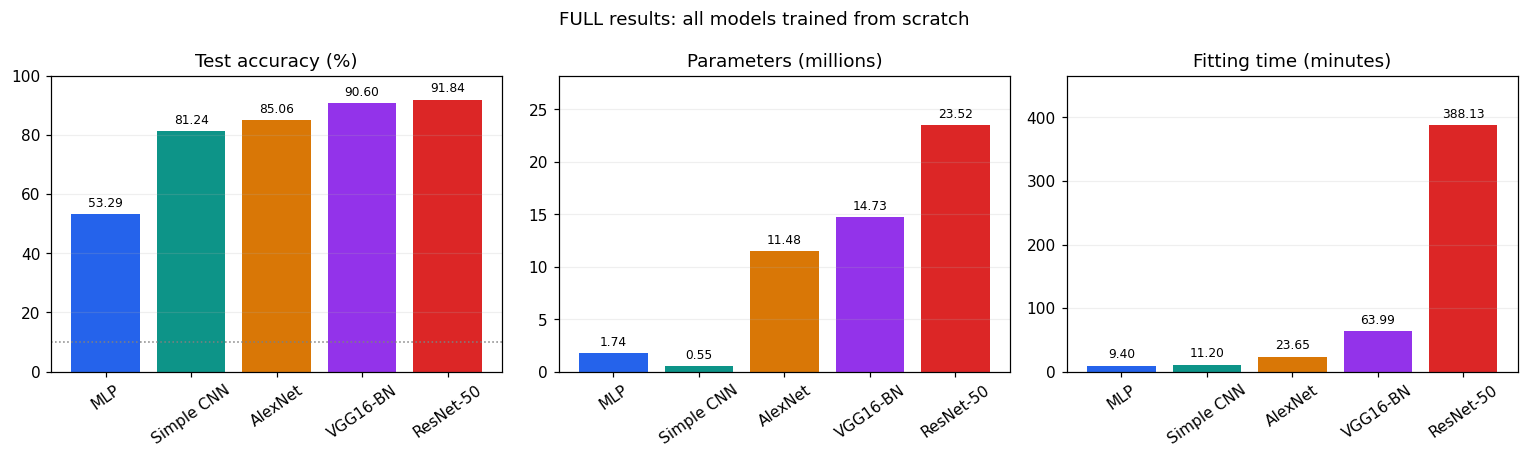

In [27]:
# Compare predictive performance, model size, and observed computational cost.
names = list(runs)
short_names = ['MLP', 'Simple CNN', 'AlexNet', 'VGG16-BN', 'ResNet-50']
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
metrics = [('Test accuracy (%)', 'Test accuracy (%)', 1),
           ('Parameters', 'Parameters (millions)', 1e6),
           ('Fit time (s)', 'Fitting time (minutes)', 60)]
for ax, (column, title, scale) in zip(axes, metrics):
    values = results.loc[names, column].to_numpy() / scale
    bars = ax.bar(short_names, values, color=[palette[name] for name in names])
    ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=3)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=35)
    ax.set_ylim(0, max(values) * 1.2)
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylim(0, 100)
axes[0].axhline(10, linestyle=':', color='gray', linewidth=1)
fig.suptitle(f'{RUN_MODE.upper()} results: all models trained from scratch', fontsize=12)
plt.tight_layout()
plt.show()

### Per-class performance and confusion matrices

Rows are true classes and columns are predictions. Entries are percentages
within each true class. The diagonal gives class recall. All heatmaps use the
same 0–100 color scale; numbers below 1% are omitted for readability.

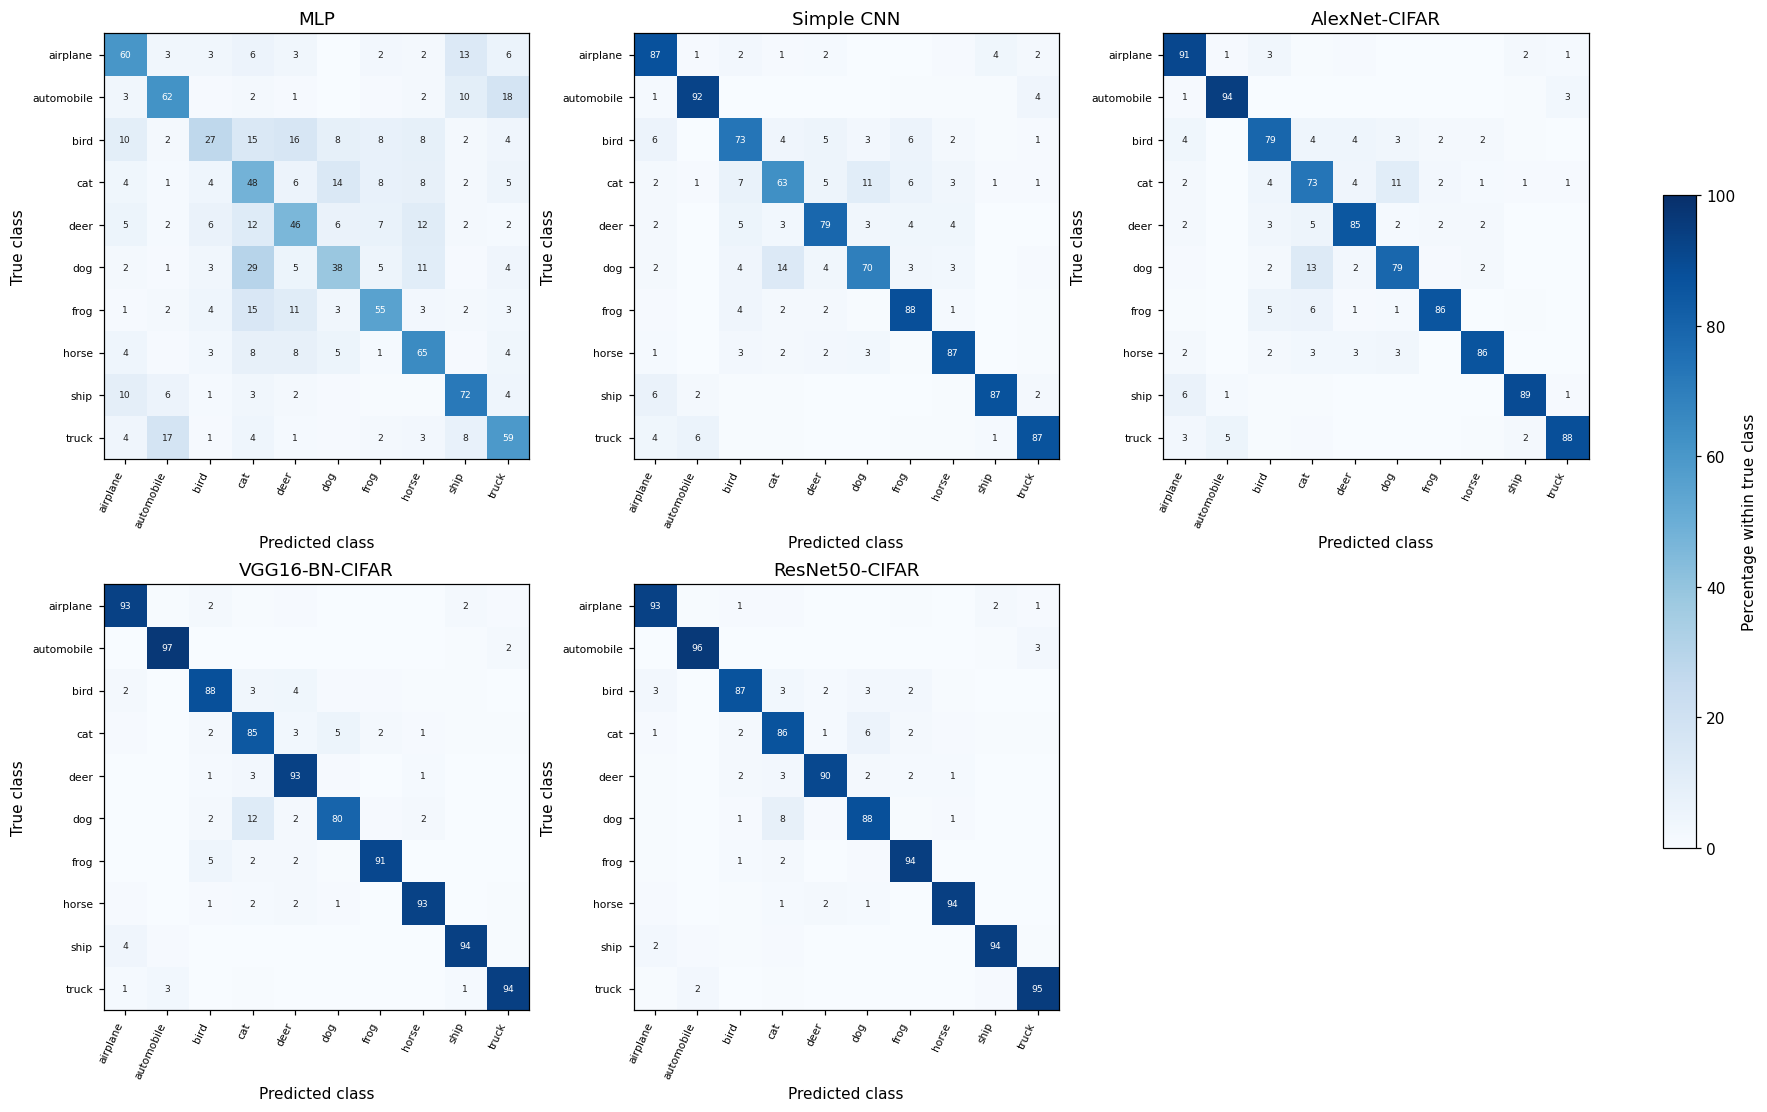

,MLP,Simple CNN,AlexNet-CIFAR,VGG16-BN-CIFAR,ResNet50-CIFAR
True class: recall (%),,,,,
airplane,60.5,87.2,90.7,93.0,93.2
automobile,62.1,92.4,94.4,96.7,96.3
bird,27.0,73.2,79.2,87.8,86.6
cat,47.8,63.1,73.3,84.7,86.5
deer,45.8,78.6,85.0,93.0,90.5
dog,38.4,69.5,78.6,79.9,87.6
frog,55.4,88.1,85.7,90.7,94.5
horse,65.0,86.6,86.3,92.7,93.9
ship,71.8,87.1,89.3,93.7,94.3


In [28]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10), layout='constrained')
per_class = {'Class': class_names}
for ax, (name, run) in zip(axes.flat, runs.items()):
    matrix = torch.bincount(10 * run['labels'] + run['predictions'], minlength=100).reshape(10, 10).numpy()
    percentages = 100 * matrix / matrix.sum(axis=1, keepdims=True)
    per_class[name] = np.diag(percentages)
    im = ax.imshow(percentages, vmin=0, vmax=100, cmap='Blues')
    for i in range(10):
        for j in range(10):
            if percentages[i, j] >= 1:
                ax.text(j, i, f'{percentages[i,j]:.0f}', ha='center', va='center', fontsize=6,
                        color='white' if percentages[i,j] > 50 else '#222222')
    ax.set(xticks=range(10), yticks=range(10), xticklabels=class_names, yticklabels=class_names,
           xlabel='Predicted class', ylabel='True class', title=name)
    plt.setp(ax.get_xticklabels(), rotation=65, ha='right', fontsize=7)
    plt.setp(ax.get_yticklabels(), fontsize=7)
axes.flat[-1].axis('off')
fig.colorbar(im, ax=list(axes.flat[:5]), shrink=0.65, label='Percentage within true class')
plt.show()
display(pd.DataFrame(per_class).set_index('Class').round(2).rename_axis('True class: recall (%)'))

### Compare predictions on identical images

Show the first test image from each true class. The examples are selected
without looking at model predictions. They illustrate behavior; use all-test
accuracy for the numerical comparison. Green text indicates a correct prediction.

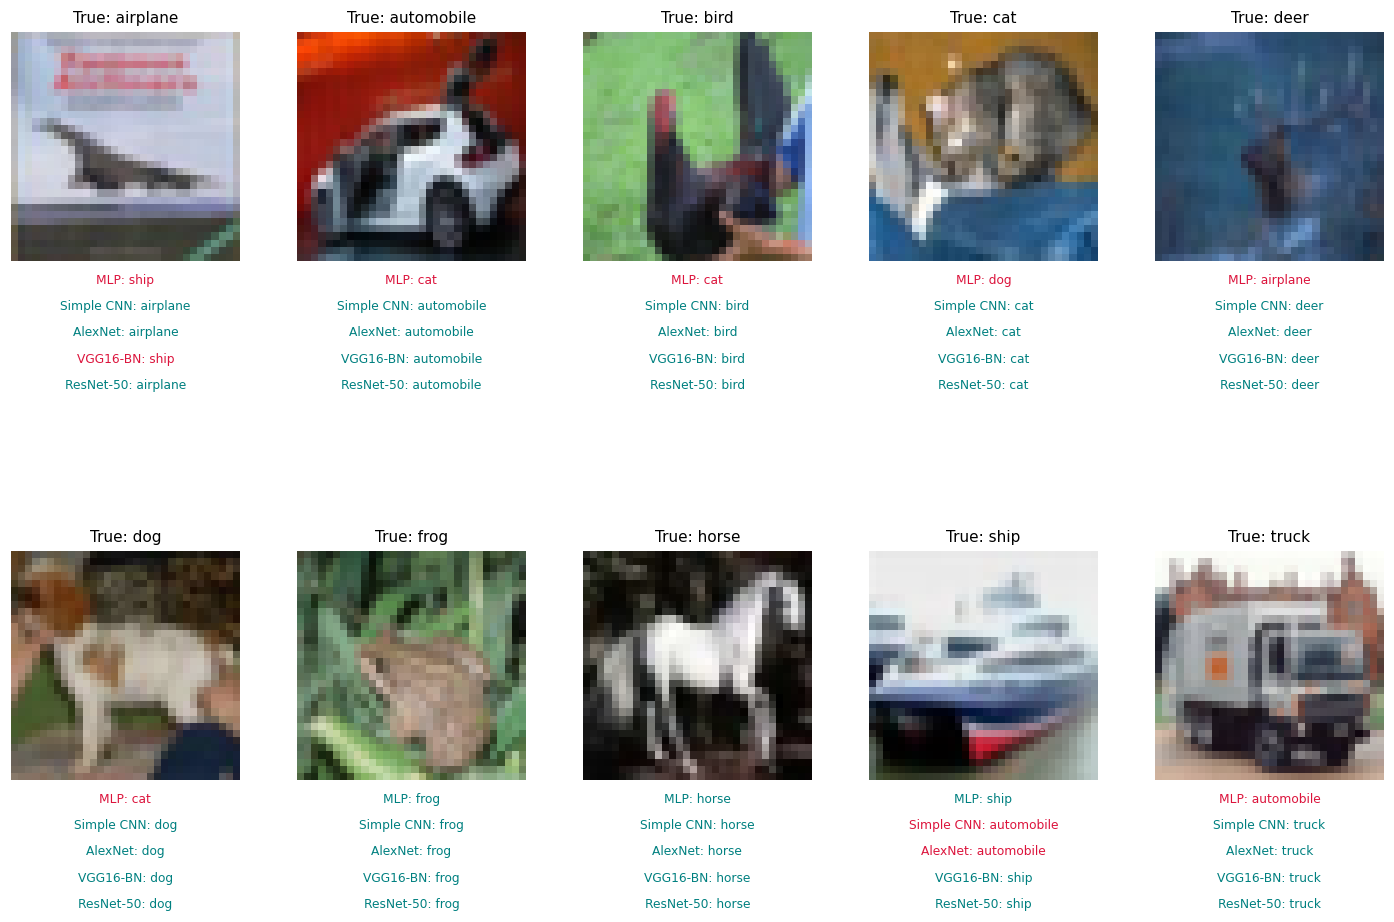

In [29]:
truth = runs['MLP']['labels']
indices = [torch.where(truth == k)[0][0].item() for k in range(10)]
fig, axes = plt.subplots(2, 5, figsize=(13, 9))
for ax, index in zip(axes.flat, indices):
    label = truth[index].item()
    ax.imshow(test_data.data[index])
    ax.set_title(f'True: {class_names[label]}', fontsize=10)
    ax.axis('off')
    for line, (name, short_name) in enumerate(zip(names, short_names)):
        prediction = runs[name]['predictions'][index].item()
        ax.text(0.5, -0.10 - 0.115 * line, f'{short_name}: {class_names[prediction]}',
                transform=ax.transAxes, ha='center', fontsize=8,
                color='teal' if prediction == label else 'crimson')
fig.subplots_adjust(left=0.03, right=0.99, top=0.94, bottom=0.16, hspace=1.05, wspace=0.25)
plt.show()

## 8. Interpretation and limitations

All five models use Adam with weight decay 1e-5 and train for 120 epochs.
The learning rate is constant at 0.001 for every model. VGG and ResNet match Kuang Liu's model definitions and
initialization. All five retain his random crop/flip augmentation and normalization.
MLP, simple CNN, and AlexNet retain the supplied definitions.

Several experimental differences remain:

| Setting | This notebook | Kuang Liu's main.py |
|---|---|---|
| Training / validation | 45,000 / 5,000 | 50,000 training; no separate validation set |
| Epochs | 120 | 200 |
| Optimizer | Adam | SGD, momentum 0.9 |
| Learning rate | Constant 0.001 for all five models | Initial 0.1; cosine schedule, T_max=200 |
| Weight decay | 1e-5 | 5e-4 |
| Checkpoint selection | Highest validation accuracy; lower CE breaks ties | Highest official test accuracy; strict improvement |
| Evaluation batch size | 128 | 100 |

Both use normalization mean (0.4914, 0.4822, 0.4465), standard deviation
(0.2023, 0.1994, 0.2010), and training batch size 128. Matching the model
architectures and preprocessing does not guarantee the repo's
reported accuracy. The settings are not individually tuned for every model.
Use validation data for tuning and keep test data out of checkpoint selection.


In [30]:
best_name = results['Test accuracy (%)'].idxmax()
best_accuracy = results.loc[best_name, 'Test accuracy (%)']
gap = best_accuracy - results.loc['MLP', 'Test accuracy (%)']
display(Markdown(
    f'For the **{RUN_MODE} run** with **{len(train_subset):,} training images** '
    f'and **{EPOCHS} epochs**, **{best_name}** had the highest observed test accuracy '
    f'(**{best_accuracy:.2f}%**), a difference of **{gap:.2f} percentage points** '
    'relative to the MLP. This descriptive ranking is based on one seed and one '
    'Adam training recipe with the same learning rate for all models; it does '
    'not select a new checkpoint or tune a model.'
))
if RUN_MODE == 'demo':
    display(Markdown(
        '**This is a small-data, short-training demonstration.** '
        'Do not use it to conclude that a deeper architecture is intrinsically better '
        'or worse. Switch to full mode for the larger experiment, then assess '
        'validation learning curves and tune using validation data.'
    ))


For the **full run** with **45,000 training images** and **120 epochs**, **ResNet50-CIFAR** had the highest observed test accuracy (**91.84%**), a difference of **38.55 percentage points** relative to the MLP. This descriptive ranking is based on one seed and one Adam training recipe with the same learning rate for all models; it does not select a new checkpoint or tune a model.

### Further comparisons

1. Inspect validation curves for convergence. Compare learning rates, schedules,
   augmentation, and regularization using validation data and comparable search
   budgets per model.
2. Repeat with prespecified seeds and summarize mean and standard deviation.
3. Treat ImageNet transfer learning as a separate experiment. These models
   start from random weights.

### Sources and implementation notes

Source snapshot checked on 2026-10-10:

- [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html)
- [Kuang Liu: VGG](https://github.com/kuangliu/pytorch-cifar/blob/master/models/vgg.py)
- [Kuang Liu: ResNet](https://github.com/kuangliu/pytorch-cifar/blob/master/models/resnet.py)
- [Kuang Liu: augmentation, optimizer, and training loop](https://github.com/kuangliu/pytorch-cifar/blob/master/main.py)

VGG16's layout/head and ResNet50's definitions follow these sources. The
current upstream training file selects SimpleDLA by default; this notebook
retains its augmentation and normalization for all five models, while using
Adam with learning rate 0.001 for every model instead of its SGD/cosine recipe.
Measured accuracies will come from executing this notebook, not these sources.

### Upstream license notice

VGG/ResNet implementation portions are adapted from kuangliu/pytorch-cifar.

```text
MIT License

Copyright (c) 2017 liukuang

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```
